# 1. Análisis Exploratorio de Datos (EDA)
## Proyecto: Clasificación de Enfermedades en Hoja de Maíz

---

## Objetivo

Comprender la composición del dataset consolidado en `data/clean/`, identificar problemas potenciales (desbalance, sesgos de captura, duplicados, calidad de imagen) y justificar las decisiones de preprocesamiento y entrenamiento del modelo.

---

## 1.1 Documentación general del dataset

> **Actualización — agosto 2026 (posterior a la primera entrega).** Este notebook refleja el
> corpus **ampliado**: se incorporaron cuatro datasets Roboflow adicionales dirigidos a las
> clases más escasas (las tres deficiencias nutricionales y GLS), pasando de **31 622** a
> **33 438 imágenes**. El desbalance máximo bajó de **32.9x** a **14.1x**.
>
> La versión de la primera entrega se conserva congelada en
> `reports/firts-phase/01_eda_first_phase.ipynb` (y su salida estática `.html`).

### Ficha técnica

| Campo | Valor |
|---|---|
| **Total de imágenes** | 33 438 |
| **Número de clases** | 9 |
| **Directorio base** | `data/clean/` |
| **Tamaño total en disco** | ~18 GB |

---

### Descripción de clases

#### Enfermedades foliares

| Clase | Nombre científico | Total | Lab | Real |
|---|---|---:|---:|---:|
| `common_rust` | *Puccinia sorghi* | 2 256 | 2 150 | 106 |
| `northern_corn_leaf_blight` | *Exserohilum turcicum* | 6 830 | 888 | 5 942 |
| `gray_leaf_spot` | *Cercospora zeae-maydis* | 1 930 | 513 | 1 417 |
| `lethal_necrosis` | MLN (*MCMV* + *SCMV*) | 6 415 | 0 | 6 415 |

#### Plagas

| Clase | Nombre científico | Total | Lab | Real |
|---|---|---:|---:|---:|
| `fall_armyworm` | *Spodoptera frugiperda* | 4 858 | 0 | 4 858 |

#### Deficiencias nutricionales

| Clase | Total | Lab | Real |
|---|---:|---:|---:|
| `nitrogen_deficiency` | 846 | 0 | 846 |
| `phosphorus_deficiency` | 938 | 0 | 938 |
| `potassium_deficiency` | 621 | 0 | 621 |

#### Control (ausencia de enfermedad)

| Clase | Total | Lab | Real |
|---|---:|---:|---:|
| `healthy` | 8 744 | 0 | 8 744 |

---

### Procedencia de las imágenes

Las imágenes provienen de **datasets públicos**. No se incluyen capturas propias. Los datasets de origen son:

| Identificador | Dataset original | Fuente |
|---|---|---|
| `corn_leaf_roboflow` | corn-leaf-roboflow | Roboflow Universe |
| `cropdg` | cropdg-unified-multidomain | CropDG (PlantVillage subset) |
| `maize_africa` | maize-beans-tomatoes-africa | Kaggle |
| `maize_desease` | maize-diseases | Kaggle |
| `maize_field` | maize-in-field-dataset | Kaggle |
| `maize_nutrient` | maize-nutrient-deficiency | Kaggle |
| `maize_2_roboflow` | maize-2-qag1o-76kth | Roboflow Universe *(ago. 2026)* |
| `maize_leaf_roboflow` | maize-leaf-7zwoi-he5vd | Roboflow Universe *(ago. 2026)* |
| `maize_deficiency_scanner_roboflow` | maize-deficiency-scanner-z2whz | Roboflow Universe *(ago. 2026)* |
| `corn_leaf_diseases_classification_roboflow` | corn-leaf-diseases-classifcation-nwmtk | Roboflow Universe *(ago. 2026)* |

> **Descartados:** `corn-leaf-diseases` (imágenes augmentadas sin originales) y `multicrop-disease` (mezcla destructiva de entornos y preprocesados sin estructura).

---

### Condiciones de captura

| Contexto | Descripción |
|---|---|
| **`lab`** | Fondo uniforme (negro/blanco/gris), entorno controlado, iluminación artificial, distancia corta y constante. Típico de PlantVillage. |
| **`real`** | Campo abierto, fondo natural variable, iluminación solar (variable), diversidad de distancias y ángulos. |

- **Resolución:** heterogénea. Las imágenes de `corn_leaf_roboflow` ya vienen redimensionadas a **640 x 640 px** (Roboflow). El resto conserva resolución original — incluidos los cuatro datasets Roboflow de agosto 2026, que **no** vienen redimensionados de forma uniforme (hasta 36 resoluciones distintas en uno de ellos, con originales de cámara de hasta 4096 x 3072 px).
- **Formato:** predominantemente JPEG/JPG, algunos PNG.
- **Naming convention:** `<clase>_<origen>_<tipo>_<correlativo>.<ext>`. En los datasets
  incorporados en agosto 2026 el sufijo no es un correlativo aleatorio sino los primeros 8
  caracteres del **SHA-256 del contenido**, para que la ingesta sea reproducible entre máquinas.

In [1]:
import importlib
import subprocess
import sys

REQUIRED = {
    "cv2":          "opencv-python-headless",
    "skimage":      "scikit-image",
    "sklearn":      "scikit-learn",
    "PIL":          "Pillow",
    "matplotlib":   "matplotlib",
    "seaborn":      "seaborn",
    "pandas":       "pandas",
    "numpy":        "numpy",
    "tqdm":         "tqdm",
    "dotenv":       "python-dotenv",
    "yaml":         "PyYAML",
    "gdown":        "gdown",
}

missing = {pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None}

if missing:
    print(f"Instalando paquetes faltantes: {', '.join(sorted(missing))}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *sorted(missing)])
    print("Instalación completada. Si hay errores de importación más abajo, reinicia el kernel.")
else:
    print("Todas las dependencias están disponibles.")


Todas las dependencias están disponibles.


In [2]:
import os
from pathlib import Path
from dotenv import load_dotenv
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import random

GDRIVE_FILE_ID = "155qQSefER_2Jhdh6DZY9kKzv3wVKtcg9"

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / ".env").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        PROJECT_ROOT = None
        break
    PROJECT_ROOT = PROJECT_ROOT.parent

if PROJECT_ROOT:
    load_dotenv(PROJECT_ROOT / ".env", override=True)

_ENV_ROOT = os.getenv("DATASET_ROOT")

if _ENV_ROOT and Path(_ENV_ROOT).exists():
    DATASET_ROOT = Path(_ENV_ROOT)
    print(f"Entorno: servidor/local (DATASET_ROOT={DATASET_ROOT})")

else:
    DATASET_ROOT = Path("/content/corn-leaf-diseases")

    if not (DATASET_ROOT / "clean").exists():
        import gdown
        import zipfile

        ZIP = Path("/content/corn-leaf-diseases-clean.zip")

        if not ZIP.exists():
            print("Descargando dataset (~14 GB)...")
            gdown.download(
                id=GDRIVE_FILE_ID,
                output=str(ZIP),
                quiet=False
            )

        print("Descomprimiendo...")
        with zipfile.ZipFile(ZIP, "r") as zf:
            zf.extractall("/content/corn-leaf-diseases")

        ZIP.unlink()
        print("Listo.")

    PROJECT_ROOT = Path("/content/maize-doctor-classifier")
    print("Entorno: Google Colab")

DATA_DIR = DATASET_ROOT / "clean"

if not Path(DATA_DIR).exists():
    raise FileNotFoundError(
        f"No se encontró {DATA_DIR}\n"
        "Verifica que DATASET_ROOT en .env apunte al dataset, o que el archivo de Drive sea accesible públicamente."
    )

TMP_DIR = (PROJECT_ROOT / "outputs" / "eda") if PROJECT_ROOT else Path("outputs/eda")
TMP_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Clean dir:    {DATA_DIR}")
print(f"Figuras:      {TMP_DIR}")

class_names = [d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))]
print(f"Clases encontradas ({len(class_names)}): {class_names}")

sns.set_theme(style="whitegrid")

Entorno: servidor/local (DATASET_ROOT=/mnt/datasets/data/corn-leaf-diseases)
Dataset root: /mnt/datasets/data/corn-leaf-diseases
Clean dir:    /mnt/datasets/data/corn-leaf-diseases/clean
Figuras:      /mnt/datasets/users/david/doctor-maiz/maize-doctor-classifier/outputs/eda
Clases encontradas (9): ['phosphorus_deficiency', 'nitrogen_deficiency', 'lethal_necrosis', 'northern_corn_leaf_blight', 'fall_armyworm', 'common_rust', 'gray_leaf_spot', 'potassium_deficiency', 'healthy']


### Muestra visual representativa por clase

Antes de analizar métricas numéricas, es útil inspeccionar visualmente ejemplos de cada clase para construir intuición sobre la variabilidad intraclase, la calidad de las etiquetas y las diferencias entre entornos de captura (lab vs campo).

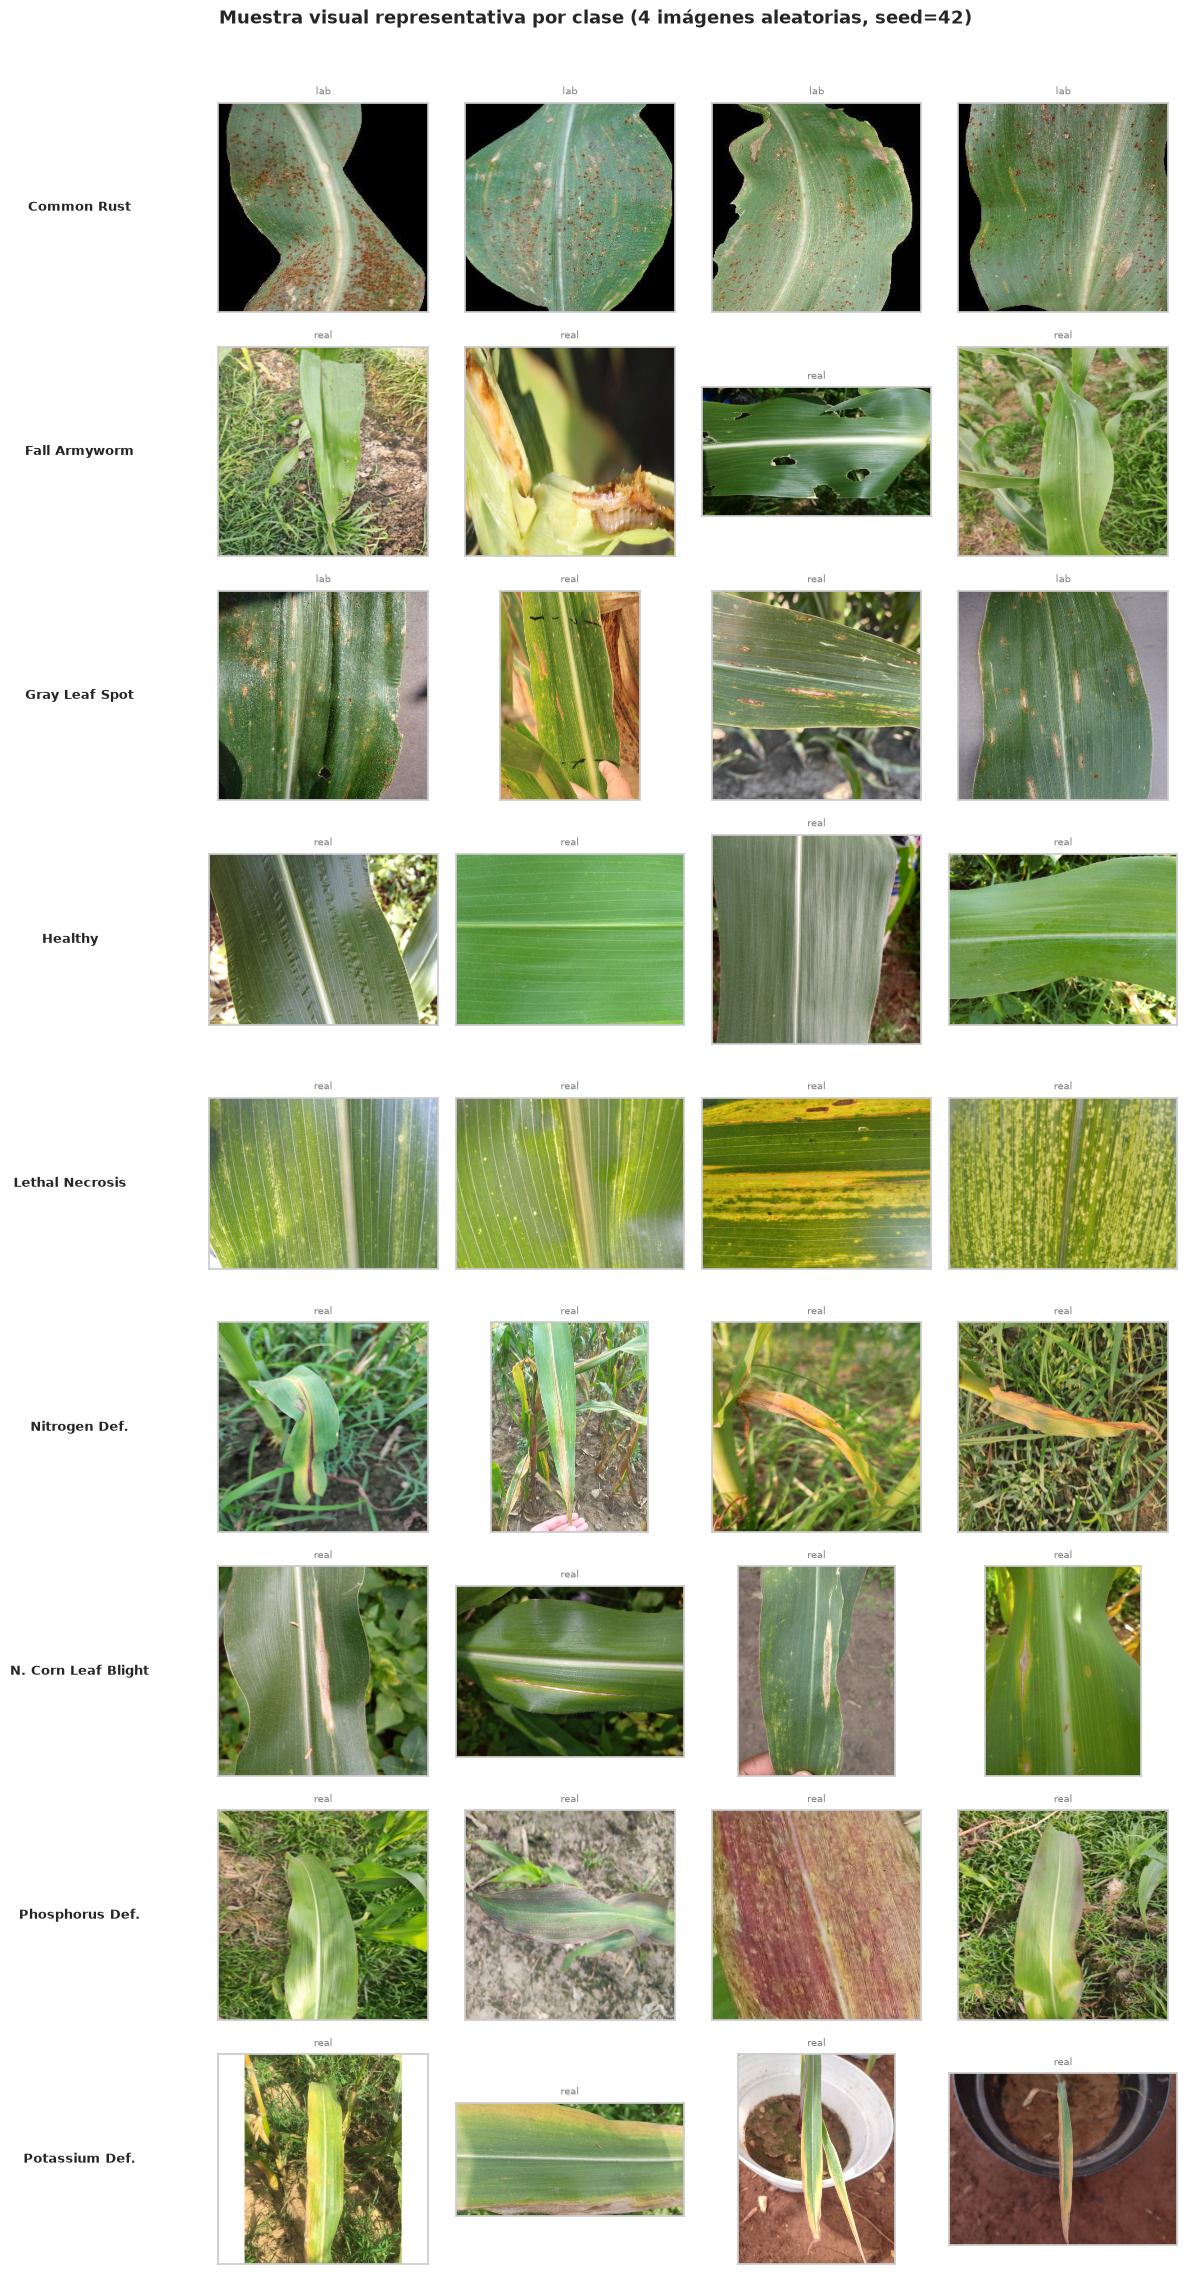

In [3]:
from PIL import Image
import random

random.seed(42)

CLEAN_DIR = Path(DATA_DIR)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}  # .tif/.tiff: alinea el conteo con src/analysis/dataset_summary.py y find_duplicates.py

CLASS_DISPLAY = {
    "common_rust": "Common Rust",
    "fall_armyworm": "Fall Armyworm",
    "gray_leaf_spot": "Gray Leaf Spot",
    "healthy": "Healthy",
    "lethal_necrosis": "Lethal Necrosis",
    "nitrogen_deficiency": "Nitrogen Def.",
    "northern_corn_leaf_blight": "N. Corn Leaf Blight",
    "phosphorus_deficiency": "Phosphorus Def.",
    "potassium_deficiency": "Potassium Def.",
}

N_EXAMPLES = 4
class_dirs = sorted([d for d in CLEAN_DIR.iterdir() if d.is_dir()])
n_classes = len(class_dirs)

fig, axes = plt.subplots(n_classes, N_EXAMPLES, figsize=(N_EXAMPLES * 3, n_classes * 2.5))

for row, class_dir in enumerate(class_dirs):
    class_name = class_dir.name
    all_imgs = [p for p in class_dir.rglob("*") if p.suffix.lower() in IMG_EXTS]
    selected = random.sample(all_imgs, min(N_EXAMPLES, len(all_imgs)))

    for col in range(N_EXAMPLES):
        ax = axes[row, col]
        if col < len(selected):
            img = cv2.cvtColor(cv2.imread(str(selected[col])), cv2.COLOR_BGR2RGB)
            ax.imshow(img)
            rel_parts = selected[col].relative_to(CLEAN_DIR).parts
            env = rel_parts[1] if len(rel_parts) > 1 else "?"
            ax.set_title(env, fontsize=7, color="gray")
        else:
            ax.axis("off")
        ax.set_xticks([])
        ax.set_yticks([])

    axes[row, 0].set_ylabel(CLASS_DISPLAY.get(class_name, class_name),
                            fontsize=9, fontweight="bold", rotation=0,
                            labelpad=100, va="center")

plt.suptitle("Muestra visual representativa por clase (4 imágenes aleatorias, seed=42)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(TMP_DIR / "eda_00_muestra_visual.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 1.2 Análisis de distribución de clases

Identificar si el dataset presenta un desbalance significativo es el primer paso antes de diseñar el pipeline de entrenamiento. Un desbalance severo puede hacer que el modelo se sesgue hacia la clase mayoritaria (ej. `healthy`), ignorando las enfermedades menos representadas.

Para mitigar este problema se utilizan técnicas como **`class_weights`** (penalizar más los errores en clases minoritarias) o muestreo ponderado (`WeightedRandomSampler`), ambas dependientes de conocer la distribución real de los datos.

Adicionalmente se desglosa el conteo entre imágenes de **laboratorio** (`lab/`) e imágenes de **campo** (`real/`), dado que ambos entornos de captura representan distribuciones visuales muy distintas y su proporción afecta directamente el riesgo de sesgo por dominio.

In [ ]:
from pathlib import Path
import matplotlib.ticker as mticker
import numpy as np

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}  # .tif/.tiff: alinea el conteo con src/analysis/dataset_summary.py y find_duplicates.py

CLEAN_DIR = Path(DATA_DIR)

EXCLUSIONS_FILE = (PROJECT_ROOT / "config" / "dataset_exclusions.csv") if PROJECT_ROOT else None
EXCLUDED = set()
if EXCLUSIONS_FILE and EXCLUSIONS_FILE.exists():
    EXCLUDED = {Path(p).as_posix() for p in pd.read_csv(EXCLUSIONS_FILE)["image_path"]}

def count_images(directory: Path) -> int:
    return sum(
        1 for f in directory.rglob("*")
        if f.suffix.lower() in IMG_EXTS and f.relative_to(DATASET_ROOT).as_posix() not in EXCLUDED
    )

records = []
for class_dir in sorted(CLEAN_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    lab_dir  = class_dir / "lab"
    real_dir = class_dir / "real"
    lab_count  = count_images(lab_dir)  if lab_dir.is_dir()  else 0
    real_count = count_images(real_dir) if real_dir.is_dir() else 0
    records.append({
        "clase":   class_dir.name,
        "lab":     lab_count,
        "real":    real_count,
        "total":   lab_count + real_count,
    })

df = pd.DataFrame(records).sort_values("total", ascending=False).reset_index(drop=True)
total_imgs = df["total"].sum()
df["porcentaje"] = (df["total"] / total_imgs * 100).round(2)

print(f"Total de imágenes: {total_imgs:,} ({len(EXCLUDED)} excluidas por contrato)\n")
print(df.to_string(index=False))

LABEL_MAP = {
    "healthy":                    "Hoja sana",
    "northern_corn_leaf_blight":  "Tizón foliar",
    "lethal_necrosis":            "Necrosis letal",
    "fall_armyworm":              "Gusano cogollero",
    "common_rust":                "Roya común",
    "gray_leaf_spot":             "Mancha gris",
    "phosphorus_deficiency":      "Deficiencia de P",
    "nitrogen_deficiency":        "Deficiencia de N",
    "potassium_deficiency":       "Deficiencia de K",
}
df["label"] = df["clase"].map(LABEL_MAP).fillna(df["clase"])

# Ordenar de mayor a menor para el gráfico horizontal
df_plot = df.sort_values("total", ascending=True).reset_index(drop=True)

palette = sns.color_palette("viridis", len(df_plot))

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(df_plot["label"], df_plot["total"], color=palette, edgecolor="white", linewidth=0.6)

for bar, total, pct in zip(bars, df_plot["total"], df_plot["porcentaje"]):
    ax.text(
        bar.get_width() + df_plot["total"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{total:,}  ({pct:.1f}%)".replace(",", " "),
        va="center", ha="left", fontsize=9, color="#333333",
    )

ax.axvline(total_imgs / len(df_plot), color="steelblue", linestyle="--", linewidth=1,
           label=f"Media: {total_imgs // len(df_plot):,} imágenes".replace(",", " "))
ax.set_title("Distribución de imágenes por clase", fontsize=14, fontweight="bold", pad=14)
ax.set_xlabel("Cantidad de imágenes", fontsize=11)
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", " ")))
ax.set_xlim(0, df_plot["total"].max() * 1.22)
ax.tick_params(axis="y", labelsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(TMP_DIR / "eda_01_distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 1.3 Análisis de origen de las imágenes (lab vs real)

La procedencia de la imagen introduce un riesgo de *atajos de aprendizaje*: si una enfermedad tiene el 95 % de sus imágenes tomadas en laboratorio con fondo blanco uniforme, la red neuronal puede aprender a identificar ese fondo en lugar del patógeno real.

Este análisis cuantifica la proporción `lab / real` por clase y detecta cuáles tienen un sesgo de dominio crítico.

In [ ]:
CLASS_ES = {
    "common_rust": "Roya común",
    "fall_armyworm": "Gusano cogollero",
    "gray_leaf_spot": "Mancha gris",
    "healthy": "Hoja sana",
    "lethal_necrosis": "Necrosis letal",
    "nitrogen_deficiency": "Deficiencia de N",
    "northern_corn_leaf_blight": "Tizón foliar",
    "phosphorus_deficiency": "Deficiencia de P",
    "potassium_deficiency": "Deficiencia de K",
}

df_origen = df[["clase", "lab", "real", "total"]].copy()
df_origen["label"] = df_origen["clase"].map(CLASS_ES).fillna(df_origen["clase"])
df_origen["pct_lab"]  = (df_origen["lab"]  / df_origen["total"] * 100).round(1)
df_origen["pct_real"] = (df_origen["real"] / df_origen["total"] * 100).round(1)

print("Proporción laboratorio / campo por clase:\n")
print(df_origen[["label", "lab", "pct_lab", "real", "pct_real", "total"]].to_string(index=False))

df_origen_sorted = df_origen.sort_values("total", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6))

lab_vals  = df_origen_sorted["pct_lab"].values
real_vals = df_origen_sorted["pct_real"].values
labels    = df_origen_sorted["label"].values

bars_lab  = ax.barh(labels, lab_vals,  color="#4C72B0", edgecolor="white", label="Laboratorio")
bars_real = ax.barh(labels, real_vals, left=lab_vals, color="#55A868", edgecolor="white", label="Campo")

for bars, vals in ((bars_lab, lab_vals), (bars_real, real_vals)):
    for bar, val in zip(bars, vals):
        if val > 5:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f"{val:.0f}%", va="center", ha="center", fontsize=9, color="white", fontweight="bold",
            )

ax.set_xlabel("Porcentaje de imágenes (%)", fontsize=11)
ax.set_title("Proporción de imágenes de laboratorio y de campo por clase", fontsize=14, fontweight="bold", pad=14)
ax.set_xlim(0, 100)
ax.tick_params(axis="y", labelsize=10)
ax.legend(fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(TMP_DIR / "eda_02_lab_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.3b Distribución por fuente de origen

Además de la segmentación lab/real, es útil visualizar cuántas imágenes aporta cada **dataset de origen** a cada clase. Esto revela concentraciones de dependencia: si una clase proviene exclusivamente de una fuente, el modelo podría sobreajustarse a las condiciones específicas de captura de esa fuente (resolución, iluminación, fondo, región geográfica).

In [ ]:
import sys

if PROJECT_ROOT and str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data.provenance import SOURCE_TO_DATASET

KNOWN_SOURCES = [
    "corn_leaf_roboflow", "maize_africa", "maize_desease", "maize_field",
    "cropdg", "maize_nutrient", "multi_desease",
    "maize_2_roboflow", "maize_leaf_roboflow",
    "maize_deficiency_scanner_roboflow", "corn_leaf_diseases_classification_roboflow",
]

CLASS_ES = {
    "common_rust": "Roya común",
    "fall_armyworm": "Gusano cogollero",
    "gray_leaf_spot": "Mancha gris",
    "healthy": "Hoja sana",
    "lethal_necrosis": "Necrosis letal",
    "nitrogen_deficiency": "Deficiencia de N",
    "northern_corn_leaf_blight": "Tizón foliar",
    "phosphorus_deficiency": "Deficiencia de P",
    "potassium_deficiency": "Deficiencia de K",
}

EXCLUSIONS_FILE = (PROJECT_ROOT / "config" / "dataset_exclusions.csv") if PROJECT_ROOT else None
excluded = set()
if EXCLUSIONS_FILE and EXCLUSIONS_FILE.exists():
    excluded = {Path(p).as_posix() for p in pd.read_csv(EXCLUSIONS_FILE)["image_path"]}

def extract_source_from_name(filepath):
    name = Path(filepath).stem
    for src in sorted(KNOWN_SOURCES, key=len, reverse=True):
        if src in name:
            return src
    return "unknown"

source_records = []
for class_dir in sorted(CLEAN_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    clase = class_dir.name
    for img_path in class_dir.rglob("*"):
        if img_path.suffix.lower() not in IMG_EXTS:
            continue
        if img_path.relative_to(DATASET_ROOT).as_posix() in excluded:
            continue
        fuente = extract_source_from_name(img_path)
        source_records.append({
            "clase": clase,
            "fuente": SOURCE_TO_DATASET.get(fuente, fuente),
        })

df_src = pd.DataFrame(source_records)
pivot = df_src.groupby(["clase", "fuente"]).size().unstack(fill_value=0)

fuente_order = pivot.sum().sort_values(ascending=False).index.tolist()
clase_order_src = pivot.sum(axis=1).sort_values(ascending=False).index.tolist()
pivot_sorted = pivot.loc[clase_order_src, fuente_order]
pivot_sorted_labels = pivot_sorted.rename(index=CLASS_ES)

fig, ax = plt.subplots(figsize=(13, 7))
annot_labels = pivot_sorted_labels.apply(lambda col: col.map(lambda v: f"{v:,}".replace(",", " ")))
sns.heatmap(pivot_sorted_labels, annot=annot_labels, fmt="", cmap="YlOrRd",
            linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "Cantidad de imágenes"})
ax.set_title("Distribución de imágenes por clase y fuente de origen",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Fuente de origen", fontsize=11)
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(TMP_DIR / "eda_02b_heatmap_fuente_clase.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Total: {len(df_src):,} imágenes ({len(excluded)} excluidas por contrato)")
for clase in pivot.index:
    nonzero = pivot.loc[clase][pivot.loc[clase] > 0]
    if len(nonzero) == 1:
        print(f"  {clase}: fuente UNICA -> {nonzero.index[0]} ({nonzero.values[0]:,} imgs)")
    elif len(nonzero) == 2:
        print(f"  {clase}: 2 fuentes -> {', '.join(f'{s} ({n:,})' for s, n in nonzero.items())}")

---

## 1.4 Análisis de resolución y dimensiones

Las redes neuronales convolucionales requieren tensores de entrada con dimensiones fijas (p.ej. 224x224 px para MobileNetV3). Conocer las dimensiones originales ayuda a entender cuánta información se perderá o distorsionará durante el redimensionamiento (*resizing*), y si existen imágenes con proporciones o tamaños anómalos.

Se usa un **muestreo estratificado** de hasta 400 imágenes por clase para acelerar el análisis sin perder representatividad.

/mnt/datasets/users/david/doctor-maiz/maize-doctor-classifier/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Total de imágenes encontradas: 33,438


Muestra para análisis de dimensiones: 3,600 imágenes


Leyendo dimensiones:   0%|          | 0/3600 [00:00<?, ?it/s]

Leyendo dimensiones:   2%|▏         | 77/3600 [00:00<00:04, 765.60it/s]

Leyendo dimensiones:   4%|▍         | 154/3600 [00:00<00:04, 690.07it/s]

... (42 outputs left out)

Leyendo dimensiones:  95%|█████████▌| 3422/3600 [00:05<00:00, 970.48it/s]

Leyendo dimensiones:  98%|█████████▊| 3521/3600 [00:05<00:00, 959.04it/s]

Leyendo dimensiones: 100%|██████████| 3600/3600 [00:05<00:00, 673.66it/s]

        width  height     mpx  aspect
count  3600.0  3600.0  3600.0  3600.0
mean   1108.8  1119.6     2.4     1.0
std    1133.6  1090.5     4.3     0.3
min      52.0    52.0     0.0     0.4
25%     480.0   467.8     0.3     0.8
50%     640.0   640.0     0.4     1.0
75%    1024.0  1080.0     1.0     1.0
max    5184.0  5120.0    20.2     5.1


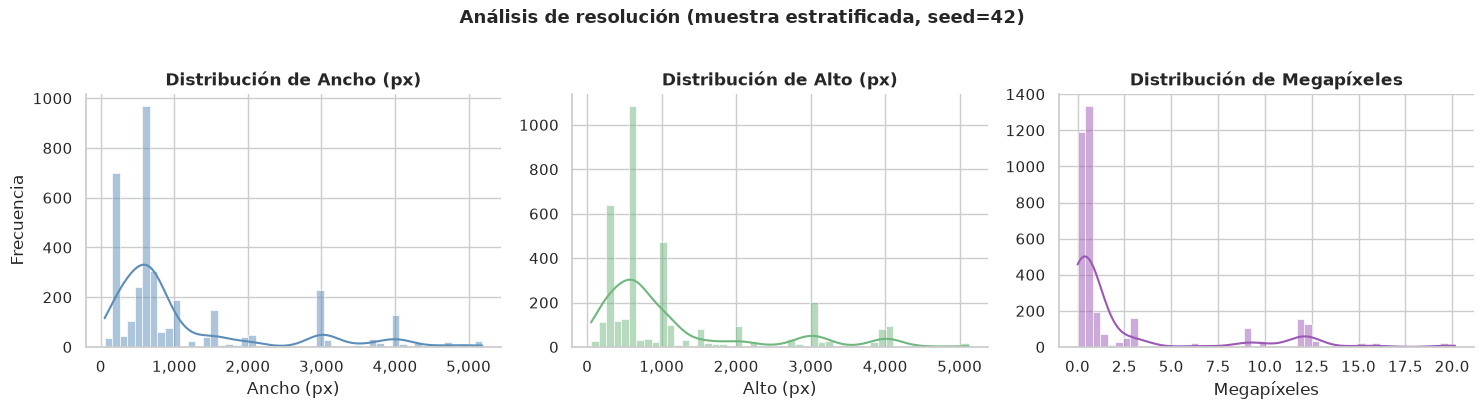


Ancho  - min: 52  max: 5,184  mediana: 640
Alto   - min: 52  max: 5,120  mediana: 640
Mpx    - min: 0.003  max: 20.155  mediana: 0.410
Aspect - min: 0.36  max: 5.11  mediana: 1.00


In [7]:
from PIL import Image
import random
from tqdm.auto import tqdm

random.seed(42)

all_images = [p for p in CLEAN_DIR.rglob("*") if p.suffix.lower() in IMG_EXTS]
print(f"Total de imágenes encontradas: {len(all_images):,}")

# Muestreo estratificado: hasta 400 por clase
SAMPLE_PER_CLASS = 400
sampled = []
for class_dir in sorted(CLEAN_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    imgs = sorted([p for p in class_dir.rglob("*") if p.suffix.lower() in IMG_EXTS])
    if len(imgs) > SAMPLE_PER_CLASS:
        imgs = random.sample(imgs, SAMPLE_PER_CLASS)
    sampled.extend(imgs)

print(f"Muestra para análisis de dimensiones: {len(sampled):,} imágenes")

dim_records = []
errors = []
for path in tqdm(sampled, desc="Leyendo dimensiones"):
    try:
        with Image.open(path) as img:
            w, h = img.size
        rel = path.relative_to(CLEAN_DIR).parts
        clase = rel[0]
        tipo  = rel[1] if len(rel) > 1 else "?"
        dim_records.append({
            "clase":  clase,
            "tipo":   tipo,
            "width":  w,
            "height": h,
            "mpx":    round(w * h / 1_000_000, 3),
            "aspect": round(w / h, 3),
        })
    except Exception as e:
        errors.append((str(path), str(e)))

df_dim = pd.DataFrame(dim_records)
if errors:
    print(f"Errores al leer: {len(errors)}")
print(df_dim.describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df_dim["width"],  bins=50, color="#5B8DB8", kde=True, ax=axes[0])
axes[0].set_title("Distribución de Ancho (px)", fontweight="bold")
axes[0].set_xlabel("Ancho (px)")
axes[0].set_ylabel("Frecuencia")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

sns.histplot(df_dim["height"], bins=50, color="#70B77E", kde=True, ax=axes[1])
axes[1].set_title("Distribución de Alto (px)", fontweight="bold")
axes[1].set_xlabel("Alto (px)")
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

sns.histplot(df_dim["mpx"], bins=50, color="#9B59B6", kde=True, ax=axes[2])
axes[2].set_title("Distribución de Megapíxeles", fontweight="bold")
axes[2].set_xlabel("Megapíxeles")
axes[2].set_ylabel("")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Análisis de resolución (muestra estratificada, seed=42)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(TMP_DIR / "eda_03_resoluciones.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nAncho  - min: {df_dim['width'].min():,}  max: {df_dim['width'].max():,}  mediana: {df_dim['width'].median():,.0f}")
print(f"Alto   - min: {df_dim['height'].min():,}  max: {df_dim['height'].max():,}  mediana: {df_dim['height'].median():,.0f}")
print(f"Mpx    - min: {df_dim['mpx'].min():.3f}  max: {df_dim['mpx'].max():.3f}  mediana: {df_dim['mpx'].median():.3f}")
print(f"Aspect - min: {df_dim['aspect'].min():.2f}  max: {df_dim['aspect'].max():.2f}  mediana: {df_dim['aspect'].median():.2f}")

### Interpretación de la distribución de resoluciones

Los histogramas revelan una distribución **claramente multimodal**, lo que refleja la heterogeneidad de las fuentes de origen:

- **Pico en ~256 px (ancho y alto):** corresponde principalmente a imágenes de `cropdg` (PlantVillage), que son capturas de laboratorio a baja resolución. Este grupo incluye la mayor parte de las imágenes de `common_rust` y `gray_leaf_spot` en entorno `lab/`.
- **Pico dominante en ~600-640 px:** asociado a `corn_leaf_roboflow`, cuyas imágenes están pre-redimensionadas a 640×640 px (cuadradas), y a `maize_nutrient` con resolución fija similar. Aquí caen las tres clases de deficiencias nutricionales y parte de `fall_armyworm`.
- **Cola larga hacia 1000-5000+ px:** imágenes de alta resolución provenientes de `maize_africa` y `maize_field`, capturadas con cámaras de campo. Incluye la mayoría de `northern_corn_leaf_blight`, `lethal_necrosis` y `healthy` en entorno `real/`.

**Implicación para el pipeline:** al redimensionar a 224×224 (target del proyecto), las imágenes del primer grupo (~256 px) apenas pierden información, mientras que las de alta resolución (~3000+ px) sufren una reducción de ~13x, perdiendo detalles finos de las lesiones. Esta asimetría puede introducir un sesgo implícito: las clases con imágenes más grandes podrían verse ligeramente degradadas respecto a las que ya venían a baja resolución, aunque el resize uniforme a `target_size` estandariza la entrada al modelo.

/tmp/ipykernel_1510860/738090712.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_dim, x="label", y="width", order=class_order_res,
/tmp/ipykernel_1510860/738090712.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_dim, x="label", y="aspect", order=class_order_res,


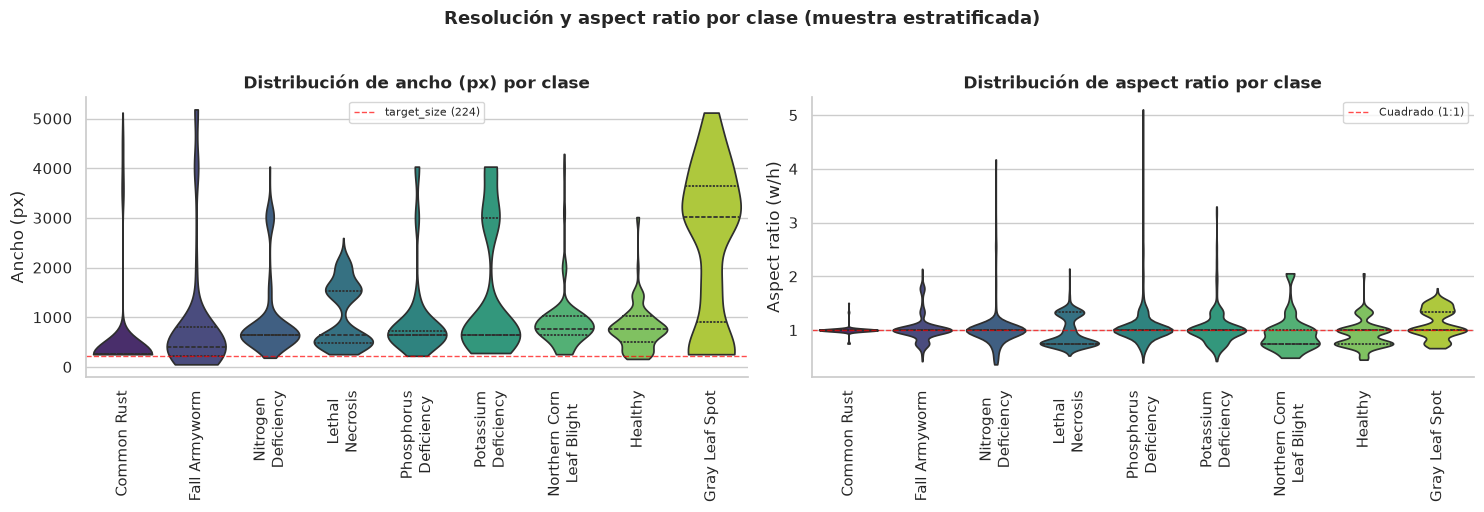

Mediana de resolución por clase:
                           median_width  median_height  median_aspect    n
clase                                                                     
common_rust                       256.0          256.0            1.0  400
fall_armyworm                     400.0          400.0            1.0  400
nitrogen_deficiency               640.0          640.0            1.0  400
lethal_necrosis                   640.0          640.0            0.8  400
phosphorus_deficiency             640.0          640.0            1.0  400
potassium_deficiency              640.0          640.0            1.0  400
northern_corn_leaf_blight         768.0         1024.0            0.8  400
healthy                           768.0         1024.0            1.0  400
gray_leaf_spot                   3024.0         2848.0            1.0  400


In [8]:
# Resolución cruzada por clase: violin plot de ancho (px)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df_dim["label"] = df_dim["clase"].map(LABEL_MAP).fillna(df_dim["clase"])
class_order_res = df_dim.groupby("label")["width"].median().sort_values().index.tolist()

sns.violinplot(data=df_dim, x="label", y="width", order=class_order_res,
               palette="viridis", inner="quartile", cut=0, ax=axes[0])
axes[0].set_title("Distribución de ancho (px) por clase", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Ancho (px)")
axes[0].tick_params(axis="x", rotation=90)
axes[0].axhline(224, color="red", linestyle="--", linewidth=1, alpha=0.7, label="target_size (224)")
axes[0].legend(fontsize=8)
axes[0].spines[["top", "right"]].set_visible(False)

sns.violinplot(data=df_dim, x="label", y="aspect", order=class_order_res,
               palette="viridis", inner="quartile", cut=0, ax=axes[1])
axes[1].set_title("Distribución de aspect ratio por clase", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Aspect ratio (w/h)")
axes[1].tick_params(axis="x", rotation=90)
axes[1].axhline(1.0, color="red", linestyle="--", linewidth=1, alpha=0.7, label="Cuadrado (1:1)")
axes[1].legend(fontsize=8)
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle("Resolución y aspect ratio por clase (muestra estratificada)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(TMP_DIR / "eda_03b_resolucion_por_clase.png", dpi=150, bbox_inches="tight")
plt.show()

# Tabla resumen de medianas por clase
res_summary = df_dim.groupby("clase").agg(
    median_width=("width", "median"),
    median_height=("height", "median"),
    median_aspect=("aspect", "median"),
    n=("width", "count")
).round(1).sort_values("median_width")
print("Mediana de resolución por clase:")
print(res_summary.to_string())

### Interpretación de resolución por clase

Los violin plots confirman que **la resolución no es independiente de la clase**, lo que tiene implicaciones directas para el pipeline:

- **Deficiencias nutricionales (N, P, K) y `fall_armyworm`** están concentradas en ~640 px (fuente `maize_nutrient` / `corn_leaf_roboflow`), con distribuciones estrechas y aspect ratio ~1.0 (cuadradas). El resize a 224×224 es una reducción moderada (~2.9x) y sin distorsión geométrica.
- **`common_rust` y `gray_leaf_spot`** tienen distribuciones bimodales: un grupo a ~256 px (lab, PlantVillage) y otro a ~640 px (Roboflow). Las imágenes de lab ya están cerca del `target_size`, mientras que las de campo pierden más información relativa.
- **`healthy`, `lethal_necrosis` y `northern_corn_leaf_blight`** presentan las colas más largas (hasta 3000-5000+ px), dominadas por imágenes de campo de alta resolución. Estas clases sufren la mayor pérdida de detalle durante el resize.

**Aspect ratio:** la mayoría de clases se concentran alrededor de 1.0 (cuadradas), pero `healthy` y `lethal_necrosis` muestran mayor dispersión (0.5-2.0), indicando mezcla de orientaciones (horizontal/vertical). El resize a cuadrado 224×224 distorsionará la geometría de las lesiones en imágenes con aspect ratio lejos de 1.0.

---

## 1.5 Análisis de calidad de imagen

Se evalúan tres métricas automáticas sobre la muestra estratificada generada en la sección anterior:

- **Desenfoque:** varianza del Laplaciano sobre la versión en escala de grises. Valores bajos (< 100) indican falta de bordes detectables - imagen borrosa.
- **Subexposición:** brillo medio (escala de grises) < 40 → imagen muy oscura / subexpuesta.
- **Sobreexposición:** brillo medio > 230 → imagen muy clara / saturada.

Estas métricas no son absolutas (una imagen de fondo negro puede tener brillo bajo siendo perfectamente válida), pero permiten identificar outliers sistemáticos por clase.

Analizando calidad:   0%|          | 0/3600 [00:00<?, ?it/s]

Analizando calidad:   0%|          | 8/3600 [00:00<02:01, 29.61it/s]

Analizando calidad:   1%|          | 19/3600 [00:00<01:28, 40.59it/s]

Analizando calidad:   1%|          | 41/3600 [00:00<00:54, 65.01it/s]

Analizando calidad:   2%|▏         | 55/3600 [00:00<00:57, 61.19it/s]

Analizando calidad:   2%|▏         | 62/3600 [00:01<01:14, 47.65it/s]

... (600 outputs left out)

Analizando calidad: 100%|█████████▉| 3595/3600 [02:09<00:00, 16.30it/s]

Analizando calidad: 100%|█████████▉| 3599/3600 [02:09<00:00, 17.58it/s]

Analizando calidad: 100%|██████████| 3600/3600 [02:09<00:00, 27.86it/s]

Imágenes analizadas: 3,600

Resumen de problemas de calidad:
  Borrosas       (blur_var < 100.0):   820  (22.8%)
  Oscuras/subexp (brightness < 40.0): 3   (0.1%)
  Sobreexpuestas (brightness > 230.0): 0  (0.0%)


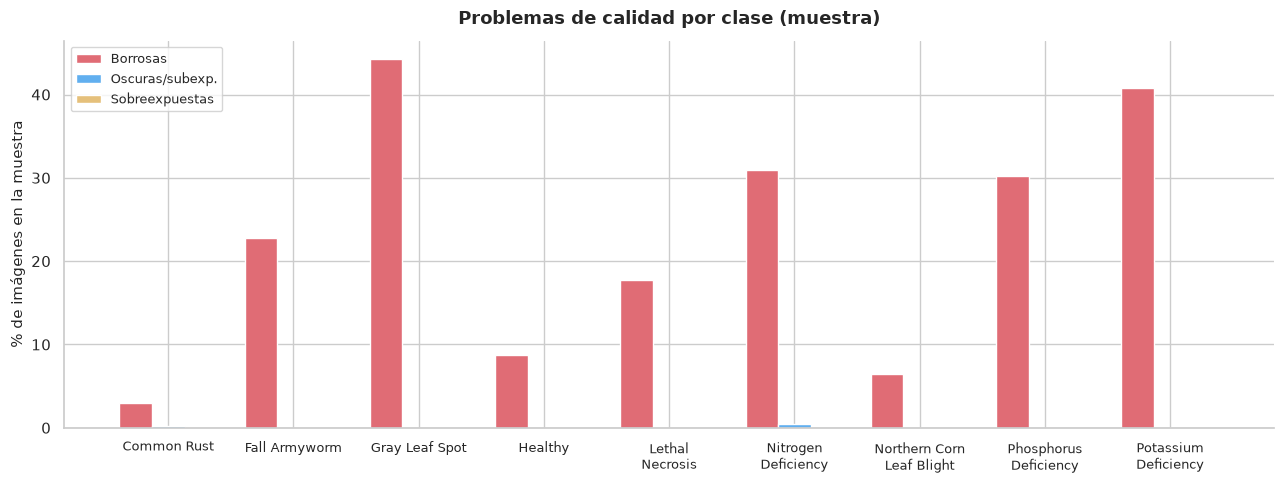

/tmp/ipykernel_1510860/3929061185.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_q, x="label", y="brightness", order=class_order,
/tmp/ipykernel_1510860/3929061185.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_q, x="label", y="blur_var", order=class_order,


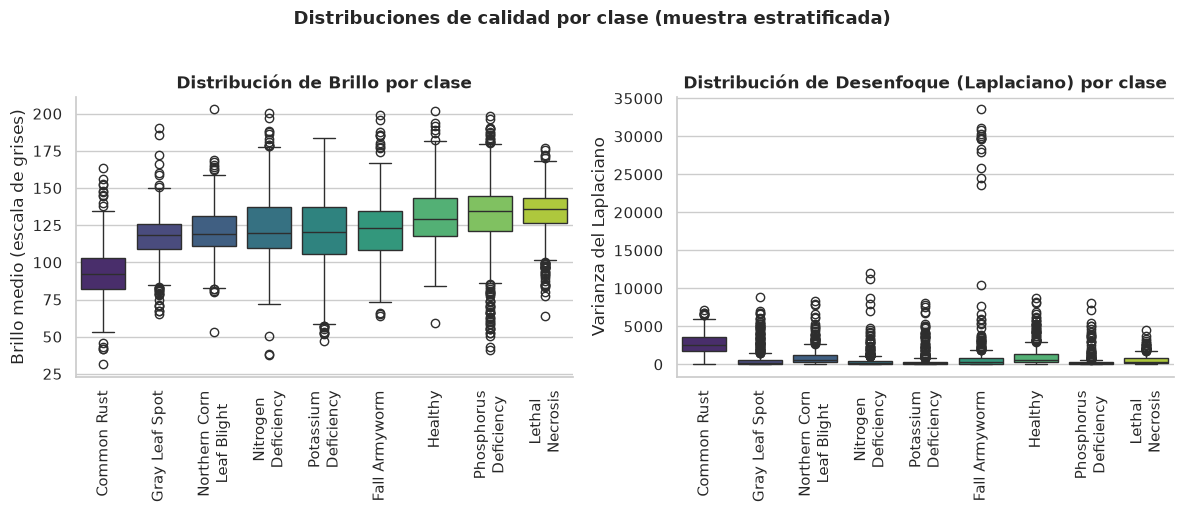

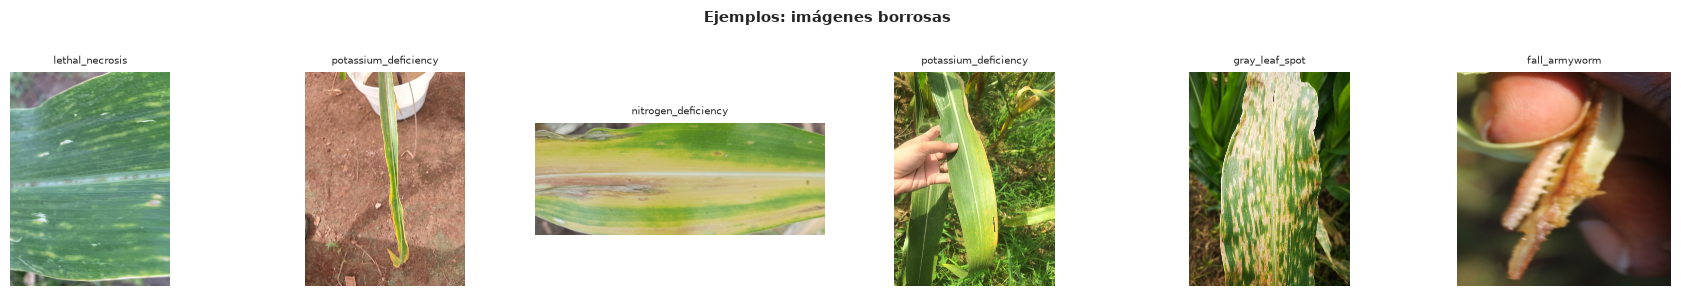

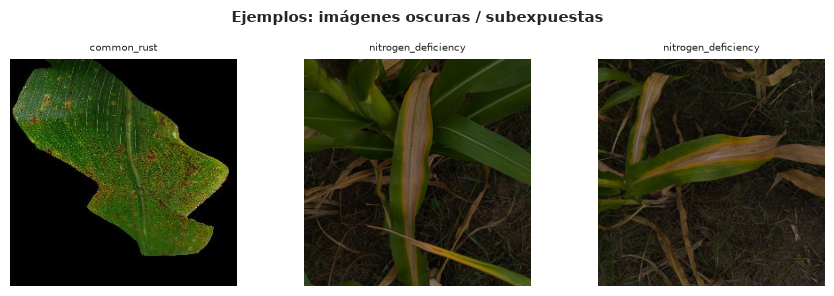

No se encontraron imágenes con: Ejemplos: imágenes sobreexpuestas


In [9]:
# Umbral absoluto: no normaliza por resolución. Imágenes grandes tendrán mayor
# varianza del Laplaciano que imágenes pequeñas a igual nivel de enfoque real.
BLUR_THRESHOLD    = 100.0
DARK_THRESHOLD    = 40.0
OVEREXP_THRESHOLD = 230.0

quality_records = []

for path in tqdm(sampled, desc="Analizando calidad"):
    try:
        img_bgr = cv2.imread(str(path))
        if img_bgr is None:
            continue
        gray       = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        blur_var   = cv2.Laplacian(gray, cv2.CV_64F).var()
        brightness = float(gray.mean())
        clase      = path.relative_to(CLEAN_DIR).parts[0]
        quality_records.append({
            "clase":      clase,
            "path":       str(path),
            "blur_var":   round(blur_var, 2),
            "brightness": round(brightness, 2),
            "is_blurry":  blur_var < BLUR_THRESHOLD,
            "is_dark":    brightness < DARK_THRESHOLD,
            "is_overexp": brightness > OVEREXP_THRESHOLD,
        })
    except Exception:
        pass

df_q = pd.DataFrame(quality_records)
print(f"Imágenes analizadas: {len(df_q):,}\n")
print("Resumen de problemas de calidad:")
print(f"  Borrosas       (blur_var < {BLUR_THRESHOLD}):   {df_q['is_blurry'].sum():,}  ({df_q['is_blurry'].mean()*100:.1f}%)")
print(f"  Oscuras/subexp (brightness < {DARK_THRESHOLD}): {df_q['is_dark'].sum():,}   ({df_q['is_dark'].mean()*100:.1f}%)")
print(f"  Sobreexpuestas (brightness > {OVEREXP_THRESHOLD}): {df_q['is_overexp'].sum():,}  ({df_q['is_overexp'].mean()*100:.1f}%)")

# Gráfico por clase: porcentaje de imágenes con problemas
quality_by_class = df_q.groupby("clase")[["is_blurry", "is_dark", "is_overexp"]].mean() * 100

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(quality_by_class))
w = 0.26
labels_q = [LABEL_MAP.get(c, c) for c in quality_by_class.index]

ax.bar(x - w,   quality_by_class["is_blurry"],  width=w, label="Borrosas",        color="#E06C75", edgecolor="white")
ax.bar(x,       quality_by_class["is_dark"],     width=w, label="Oscuras/subexp.", color="#61AFEF", edgecolor="white")
ax.bar(x + w,   quality_by_class["is_overexp"],  width=w, label="Sobreexpuestas",  color="#E5C07B", edgecolor="white")

ax.set_xticks(x)
ax.set_xticklabels(labels_q, fontsize=9)
ax.set_ylabel("% de imágenes en la muestra", fontsize=11)
ax.set_title("Problemas de calidad por clase (muestra)", fontsize=13, fontweight="bold", pad=12)
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(TMP_DIR / "eda_04_calidad.png", dpi=150, bbox_inches="tight")
plt.show()

# Boxplots de distribución de brillo y desenfoque por clase
df_q["label"] = df_q["clase"].map(LABEL_MAP).fillna(df_q["clase"])
class_order = df_q.groupby("label")["brightness"].median().sort_values().index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df_q, x="label", y="brightness", order=class_order,
            palette="viridis", ax=axes[0])
axes[0].set_title("Distribución de Brillo por clase", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Brillo medio (escala de grises)")
axes[0].tick_params(axis="x", rotation=90)
axes[0].spines[["top", "right"]].set_visible(False)

sns.boxplot(data=df_q, x="label", y="blur_var", order=class_order,
            palette="viridis", ax=axes[1])
axes[1].set_title("Distribución de Desenfoque (Laplaciano) por clase", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Varianza del Laplaciano")
axes[1].tick_params(axis="x", rotation=90)
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle("Distribuciones de calidad por clase (muestra estratificada)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(TMP_DIR / "eda_04b_calidad_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

# Ejemplos visuales de imágenes con problemas
def show_flagged_examples(df_quality, flag_col, title, n=6):
    flagged = df_quality[df_quality[flag_col]]["path"].tolist()
    if not flagged:
        print(f"No se encontraron imágenes con: {title}")
        return
    sample = random.sample(flagged, min(n, len(flagged)))
    fig, axes = plt.subplots(1, len(sample), figsize=(3 * len(sample), 3))
    if len(sample) == 1:
        axes = [axes]
    for ax, p in zip(axes, sample):
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(Path(p).relative_to(CLEAN_DIR).parts[0], fontsize=7)
        ax.axis("off")
    fig.suptitle(title, fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

show_flagged_examples(df_q, "is_blurry",  "Ejemplos: imágenes borrosas")
show_flagged_examples(df_q, "is_dark",    "Ejemplos: imágenes oscuras / subexpuestas")
show_flagged_examples(df_q, "is_overexp", "Ejemplos: imágenes sobreexpuestas")

### Interpretación de los resultados de calidad

**El desenfoque es el único problema de calidad significativo en el dataset.** Las categorías de subexposición y sobreexposición son prácticamente inexistentes (ambas ~0% del total), lo que indica que las condiciones de iluminación de las fuentes son aceptables en general. En contraste, el blur afecta de forma desigual a las clases:

- **`gray_leaf_spot` es la clase más afectada** (~38% de imágenes borrosas), seguida de `nitrogen_deficiency` (~28%) y `potassium_deficiency` (~21%). Estas son precisamente clases minoritarias, lo que agrava el problema: no solo tienen pocas imágenes, sino que una proporción alta de ellas tiene baja calidad.
- **`common_rust` tiene la menor tasa de blur** (~2%), consistente con su origen mayoritariamente de laboratorio (condiciones controladas, distancia fija, enfoque constante).

**Hallazgo clave en los boxplots de brillo:** `common_rust` presenta un brillo mediano notablemente inferior (~95) comparado con el resto de las clases (~120-140). Esto es una **evidencia cuantitativa directa del sesgo de dominio** identificado en la sección 1.3: sus imágenes de laboratorio utilizan fondos oscuros (negro/gris) que bajan el brillo global de la imagen. Si el modelo aprende a asociar brillo bajo con `common_rust`, fallará sistemáticamente en imágenes de campo donde las hojas aparecen con fondo de vegetación (brillo medio-alto).

> **Nota metodológica:** el umbral de blur (varianza del Laplaciano < 100) es un valor absoluto que no normaliza por resolución. Imágenes de alta resolución naturalmente tienen mayor varianza del Laplaciano que imágenes pequeñas, lo que podría subestimar el blur en imágenes de baja resolución (~256 px) y sobreestimarlo en imágenes grandes (~3000+ px). Los resultados deben interpretarse como una aproximación, no como una medida calibrada.

### 1.5b Análisis de distribución de color (canal Hue) por clase

En un problema de clasificación de enfermedades foliares, el color es una señal diagnóstica primaria: `common_rust` produce pústulas **anaranjadas**, `nitrogen_deficiency` causa **amarillamiento** generalizado, y `gray_leaf_spot` genera manchas **grisáceas**. Analizar la distribución del canal Hue (HSV) por clase permite verificar si estas firmas cromáticas son detectables estadísticamente y si existen diferencias de dominio de color entre imágenes lab y real.

Imágenes analizadas para color: 900


/tmp/ipykernel_1510860/4013099078.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_color, x="label", y=col, order=class_order_color,
/tmp/ipykernel_1510860/4013099078.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_color, x="label", y=col, order=class_order_color,
/tmp/ipykernel_1510860/4013099078.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_color, x="label", y=col, order=class_order_color,


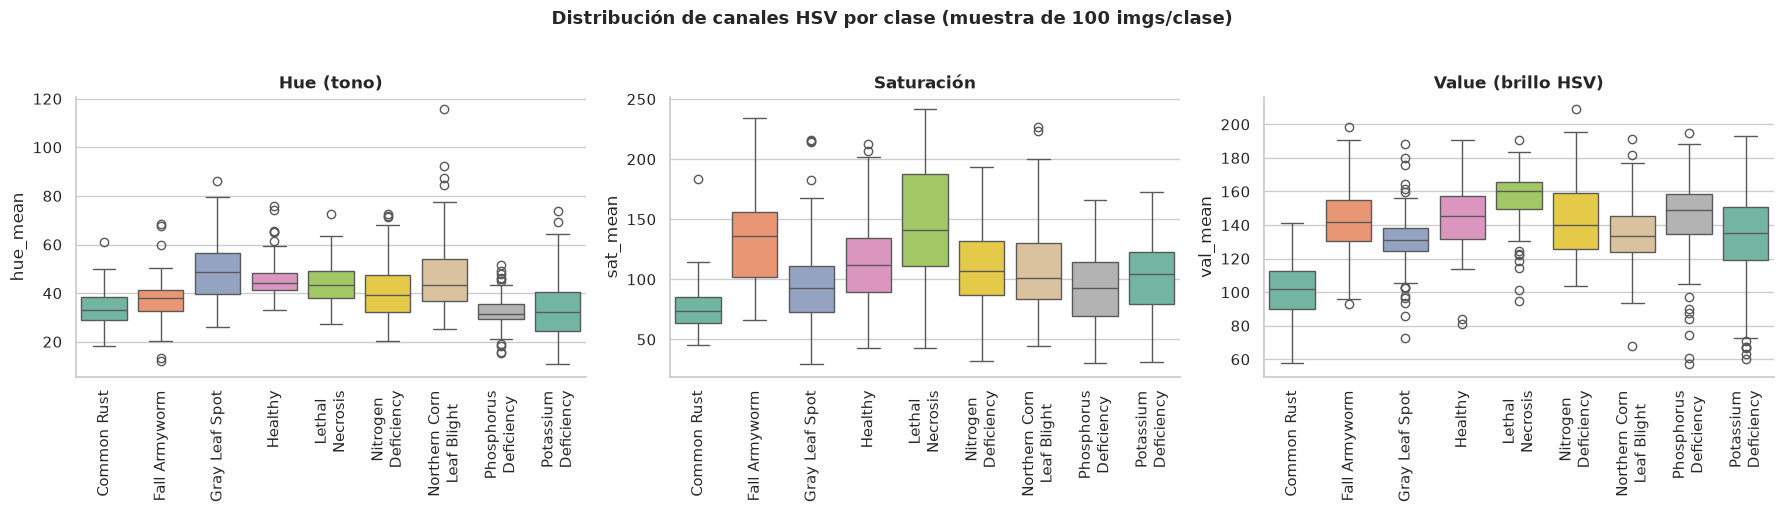

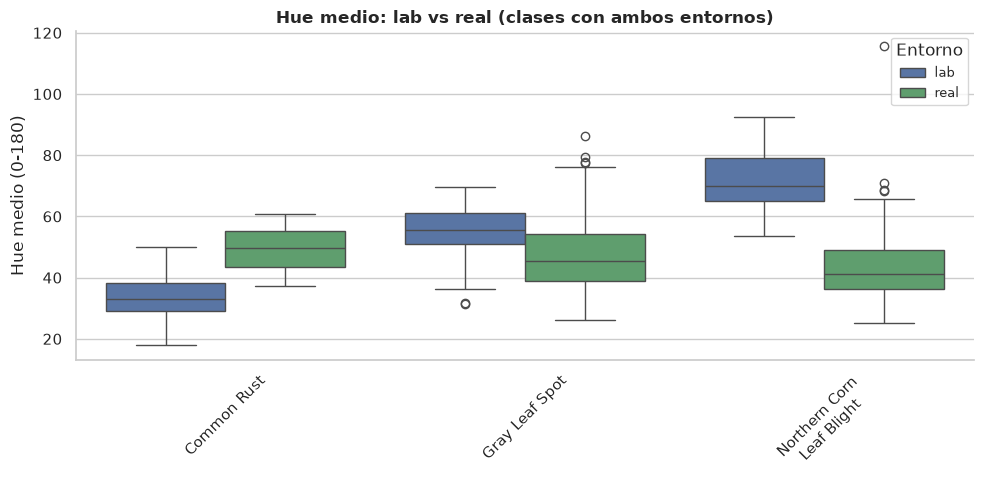


Mediana de canales HSV por clase:
                           hue_median  sat_median  val_median
clase                                                        
phosphorus_deficiency            31.4        92.6       148.9
potassium_deficiency             32.4       104.7       135.1
common_rust                      33.2        73.3       101.8
fall_armyworm                    37.8       136.3       141.6
nitrogen_deficiency              39.2       106.8       140.1
northern_corn_leaf_blight        43.2       101.5       133.7
lethal_necrosis                  43.4       141.2       160.4
healthy                          44.0       111.7       145.1
gray_leaf_spot                   48.7        92.5       131.0


In [10]:
COLOR_SAMPLE = 100

hue_records = []
for class_dir in sorted(CLEAN_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    clase = class_dir.name
    imgs = [p for p in class_dir.rglob("*") if p.suffix.lower() in IMG_EXTS]
    if len(imgs) > COLOR_SAMPLE:
        imgs = random.sample(imgs, COLOR_SAMPLE)
    for path in imgs:
        try:
            img_bgr = cv2.imread(str(path))
            if img_bgr is None:
                continue
            img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
            h_mean = float(img_hsv[:, :, 0].mean())
            s_mean = float(img_hsv[:, :, 1].mean())
            v_mean = float(img_hsv[:, :, 2].mean())
            rel = path.relative_to(CLEAN_DIR).parts
            env = rel[1] if len(rel) > 1 else "?"
            hue_records.append({
                "clase": clase, "env": env,
                "hue_mean": round(h_mean, 1),
                "sat_mean": round(s_mean, 1),
                "val_mean": round(v_mean, 1),
            })
        except Exception:
            pass

df_color = pd.DataFrame(hue_records)
df_color["label"] = df_color["clase"].map(LABEL_MAP).fillna(df_color["clase"])
print(f"Imágenes analizadas para color: {len(df_color):,}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
channels = [("hue_mean", "Hue (tono)", "Set2"), ("sat_mean", "Saturación", "Set2"), ("val_mean", "Value (brillo HSV)", "Set2")]
class_order_color = sorted(df_color["label"].unique())

for ax, (col, title, pal) in zip(axes, channels):
    sns.boxplot(data=df_color, x="label", y=col, order=class_order_color,
                palette=pal, ax=ax)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=90)
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Distribución de canales HSV por clase (muestra de 100 imgs/clase)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(TMP_DIR / "eda_04c_color_hsv.png", dpi=150, bbox_inches="tight")
plt.show()

# Hue por clase y entorno (lab vs real) para clases que tienen ambos
classes_both_env = df_color.groupby("clase")["env"].nunique()
classes_both = classes_both_env[classes_both_env > 1].index.tolist()

if classes_both:
    df_both = df_color[df_color["clase"].isin(classes_both)]
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(data=df_both, x="label", y="hue_mean", hue="env",
                palette={"lab": "#4C72B0", "real": "#55A868"}, ax=ax)
    ax.set_title("Hue medio: lab vs real (clases con ambos entornos)", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Hue medio (0-180)")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title="Entorno", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(TMP_DIR / "eda_04d_hue_lab_vs_real.png", dpi=150, bbox_inches="tight")
    plt.show()

# Tabla resumen
color_summary = df_color.groupby("clase").agg(
    hue_median=("hue_mean", "median"),
    sat_median=("sat_mean", "median"),
    val_median=("val_mean", "median"),
).round(1).sort_values("hue_median")
print("\nMediana de canales HSV por clase:")
print(color_summary.to_string())

---

## 1.6 Detección de duplicados y limpieza

Los duplicados fueron identificados y eliminados durante la etapa de limpieza del dataset utilizando **hash perceptual (pHash)** con la librería `imagededup` (threshold = 0, solo copias exactas a nivel perceptual). El proceso se ejecuta por clase completa (lab + real juntos) y los resultados se almacenan en el repositorio: `src/cleanup/results/`.

### Criterios de exclusión aplicados

Durante la revisión manual y automática se descartaron imágenes que presentaban alguna de las siguientes condiciones:

1. **Imágenes aumentadas** sin su original: datasets como `corn-leaf-diseases` solo publicaron versiones con augmentation (flip, rotación, brillo), haciendo imposible separar los originales.
2. **Metadatos inconsistentes o etiquetas erróneas:** imágenes etiquetadas con una clase pero con síntomas de otra (mezcla destructiva).
3. **Elementos fuera de clase:** presencia de tarjetas de identificación, marcadores de escala, objetos no relacionados con la hoja de maíz.
4. **Mezcla de entornos sin estructura recuperable:** datasets que combinaron lab y real sin naming convention consistente (ej. `multicrop-disease`).

### Data leakage entre datasets

Un hallazgo crítico fue la presencia de duplicados **entre datasets distintos**: varias imágenes de `maize_desease` y `multi_desease` son copias perceptuales idénticas de imágenes presentes en otras fuentes (principalmente `maize_africa` y `maize_field`). Incluir ambas versiones en train y val generaría *data leakage* directo, inflando artificialmente las métricas de validación.

### Resultados cuantitativos por fuente

| Fuente | Imágenes eliminadas (aprox.) |
|---|---:|
| `maize_desease` | ~6 508 |
| `multi_desease` | ~1 980 |
| `maize_africa` | ~51 |
| `maize_field` | ~23 |
| `cropdg` | ~1 |

> Total eliminado: **8 538 imágenes** en **8 050 grupos** de duplicados. El dataset actual en `data/clean/` es **post-deduplicación**.

In [11]:
import csv
import json
import re
from collections import defaultdict

#  Configuración 
GDRIVE_RESULTS_FILE_ID = "1Erz4TivvmEJRr1LHwzqq8-UCFGc8BErB"

#  Localizar carpeta de resultados 
_REPO_RESULTS  = Path("../src/cleanup/results")
_COLAB_RESULTS = Path("/content/cleanup_results")

if _REPO_RESULTS.exists():
    RESULTS_DIR = _REPO_RESULTS
    print(f"Entorno: servidor/local (resultados en {RESULTS_DIR.resolve()})")
else:
    # Google Colab: descargar ZIP de resultados desde Drive
    import gdown, zipfile
    ZIP_R = Path("/content/cleanup_results.zip")
    if not _COLAB_RESULTS.exists():
        if not ZIP_R.exists():
            print("Descargando resultados de duplicados desde Drive...")
            gdown.download(id=GDRIVE_RESULTS_FILE_ID, output=str(ZIP_R), quiet=False)
        print("Descomprimiendo resultados...")
        with zipfile.ZipFile(ZIP_R, "r") as zf:
            zf.extractall("/content/cleanup_results")
        ZIP_R.unlink()
        print("Listo.")
    # El ZIP puede contener una subcarpeta (ej. results/) - buscar dónde están los CSVs
    csv_candidates = list(_COLAB_RESULTS.rglob("duplicates_*.csv"))
    RESULTS_DIR = csv_candidates[0].parent if csv_candidates else _COLAB_RESULTS
    print(f"Entorno: Google Colab (resultados en {RESULTS_DIR.resolve()})")

#  Fuentes conocidas del proyecto 
KNOWN_SOURCES = [
    "corn_leaf_roboflow", "maize_africa", "maize_desease", "maize_field",
    "cropdg", "maize_nutrient", "multi_desease",
    # Ampliación agosto 2026 (posterior a la primera entrega)
    "maize_2_roboflow", "maize_leaf_roboflow",
    "maize_deficiency_scanner_roboflow", "corn_leaf_diseases_classification_roboflow",
]

def extract_source(filepath: str) -> str:
    name = Path(filepath).stem
    for src in sorted(KNOWN_SOURCES, key=len, reverse=True):
        if src in name:
            return src
    return "unknown"

def clase_from_filename(filename: str) -> str:
    stem = Path(filename).stem  # duplicates_CLASE_20260608_160954
    return re.sub(r"_\d{8}_\d{6}$", "", stem.replace("duplicates_", ""))

#  Procesar todos los CSVs 
dup_summary = defaultdict(lambda: {"groups": 0, "eliminated": 0, "by_source": defaultdict(int)})

csv_files = sorted(RESULTS_DIR.glob("duplicates_*.csv"))
print(f"\nArchivos CSV encontrados: {len(csv_files)}")

for csv_path in csv_files:
    clase = clase_from_filename(csv_path.name)
    with open(csv_path, newline="", encoding="utf-8") as fh:
        reader = csv.DictReader(fh)
        for row in reader:
            dups = json.loads(row["duplicate_paths"])
            dup_summary[clase]["groups"] += 1
            dup_summary[clase]["eliminated"] += len(dups)
            for dup_path in dups:
                src = extract_source(dup_path)
                dup_summary[clase]["by_source"][src] += 1

#  Tabla resumen 
df_dups = pd.DataFrame([
    {
        "clase":      clase,
        "grupos":     info["groups"],
        "eliminados": info["eliminated"],
        "fuentes":    ", ".join(f"{s}:{n}" for s, n in sorted(info["by_source"].items())),
    }
    for clase, info in sorted(dup_summary.items())
])

total_elim   = df_dups["eliminados"].sum()
total_grupos = df_dups["grupos"].sum()

print(f"\nTotal de grupos de duplicados detectados: {total_grupos:,}")
print(f"Total de imágenes eliminadas:             {total_elim:,}\n")
print(df_dups.to_string(index=False))

Entorno: servidor/local (resultados en /mnt/datasets/users/david/doctor-maiz/maize-doctor-classifier/src/cleanup/results)

Archivos CSV encontrados: 12

Total de grupos de duplicados detectados: 8,110
Total de imágenes eliminadas:             8,599

                    clase  grupos  eliminados                                                                                                 fuentes
              common_rust     971        1048                                                                       maize_field:1, multi_desease:1047
            fall_armyworm     548         958                                                                      maize_africa:25, multi_desease:933
           gray_leaf_spot     560         560 corn_leaf_diseases_classification_roboflow:20, maize_desease:513, maize_field:22, maize_leaf_roboflow:5
                  healthy    1773        1774                                                           cropdg:1, maize_africa:26, maize_desease:1747


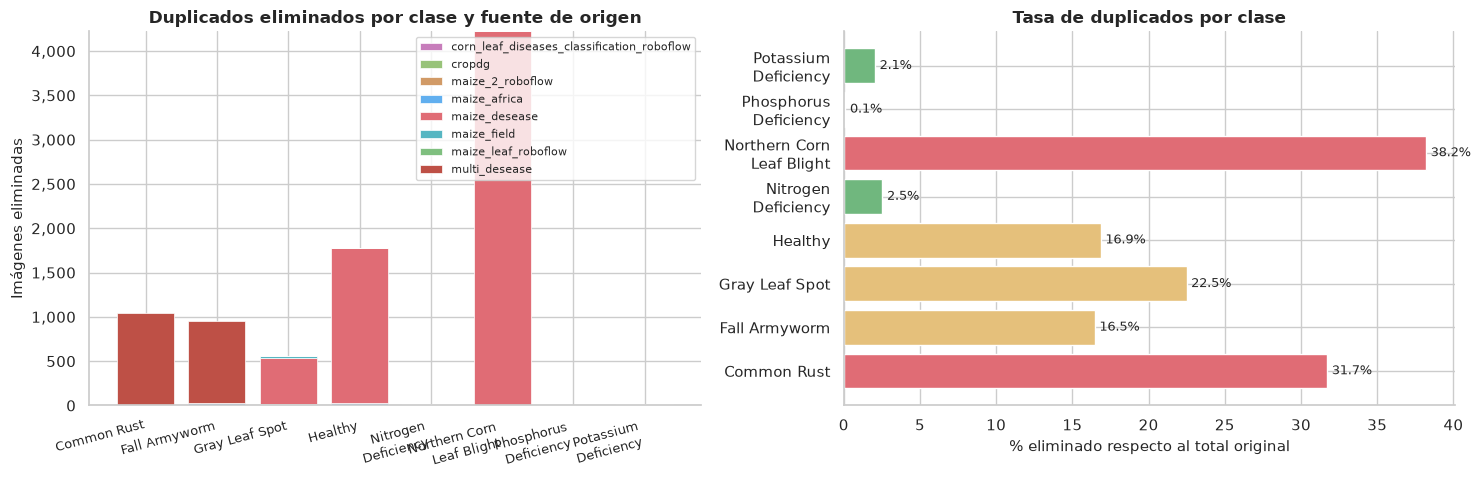


Método: pHash (imagededup), threshold=0 (solo copias exactas perceptualmente).
Total eliminado: 8,599 imágenes en 8,110 grupos.


In [12]:
#  Gráfico: duplicados eliminados por clase 
all_sources = sorted({src for info in dup_summary.values() for src in info["by_source"]})
clases_dup  = sorted(dup_summary.keys())

source_colors = {
    "maize_desease":  "#E06C75",
    "multi_desease":  "#BE5046",
    "maize_africa":   "#61AFEF",
    "maize_field":    "#56B6C2",
    "cropdg":         "#98C379",
    "corn_leaf_roboflow": "#E5C07B",
    "maize_nutrient": "#C678DD",
    "maize_2_roboflow": "#D19A66",
    "maize_leaf_roboflow": "#7FBF7F",
    "maize_deficiency_scanner_roboflow": "#5C9DD6",
    "corn_leaf_diseases_classification_roboflow": "#C77DBB",
    "unknown":        "#ABB2BF",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Izquierda: barras apiladas por fuente
bottom = np.zeros(len(clases_dup))
x = np.arange(len(clases_dup))
for src in all_sources:
    vals = [dup_summary[c]["by_source"].get(src, 0) for c in clases_dup]
    axes[0].bar(x, vals, bottom=bottom, label=src,
                color=source_colors.get(src, "#ABB2BF"), edgecolor="white", linewidth=0.5)
    bottom += np.array(vals)

axes[0].set_xticks(x)
axes[0].set_xticklabels([LABEL_MAP.get(c, c) for c in clases_dup], fontsize=9, rotation=15, ha="right")
axes[0].set_ylabel("Imágenes eliminadas", fontsize=11)
axes[0].set_title("Duplicados eliminados por clase y fuente de origen", fontsize=12, fontweight="bold")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
axes[0].legend(fontsize=8, loc="upper right")
axes[0].spines[["top", "right"]].set_visible(False)

# Derecha: % de duplicados respecto al total original (antes de limpiar)
df_pct = df.set_index("clase").reindex(clases_dup)
orig_totals = {
    c: df_pct.loc[c, "total"] + dup_summary[c]["eliminated"]
    for c in clases_dup if c in df_pct.index
}
pcts = [dup_summary[c]["eliminated"] / orig_totals[c] * 100 if c in orig_totals else 0
        for c in clases_dup]
bar_colors = ["#E06C75" if p > 30 else "#E5C07B" if p > 10 else "#70B77E" for p in pcts]
axes[1].barh([LABEL_MAP.get(c, c) for c in clases_dup], pcts, color=bar_colors, edgecolor="white")
axes[1].set_xlabel("% eliminado respecto al total original", fontsize=11)
axes[1].set_title("Tasa de duplicados por clase", fontsize=12, fontweight="bold")
axes[1].spines[["top", "right"]].set_visible(False)
for i, p in enumerate(pcts):
    axes[1].text(p + 0.3, i, f"{p:.1f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(TMP_DIR / "eda_05_duplicados.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nMétodo: pHash (imagededup), threshold=0 (solo copias exactas perceptualmente).")
print(f"Total eliminado: {total_elim:,} imágenes en {total_grupos:,} grupos.")

---

## 1.7 Identificación de posibles sesgos

A partir de la distribución por clases y del análisis de origen (laboratorio vs campo), se identifican varios sesgos que pueden afectar el entrenamiento y la generalización del modelo.

### Tipos de sesgo identificados

1. **Desbalance de clases:** La clase `healthy` (8 744 imágenes) supera en **14.1x** a `potassium_deficiency` (621). Este desequilibrio obliga a usar estrategias como `class_weights='balanced'` o `WeightedRandomSampler` para que el modelo no ignore las clases minoritarias. *(Tras la ampliación de agosto 2026 el ratio bajó desde 32.9x, pero el desbalance sigue siendo severo y las cuatro clases reforzadas continúan por encima del umbral de 4x que activa el pipeline extendido de augmentación.)*

2. **Sesgo de entorno (lab vs campo):** `common_rust` tiene el **95.4 %** de sus imágenes tomadas en laboratorio (fondo blanco/negro uniforme). El modelo puede aprender el fondo en lugar de los síntomas, colapsando en condiciones de campo. Se recomienda augmentation con fondos aleatorios y ampliar las imágenes reales.

3. **Riesgo de dominio y sobreajuste a la fuente:** Clases como `northern_corn_leaf_blight` concentran la mayoría de imágenes reales en un único dataset geográfico (`maize_africa`). Esto limita la variabilidad de condiciones de luz, suelo y clima, aumentando el riesgo de sobreajuste a ese dominio específico.

4. **Heterogeneidad visual intraclase en `fall_armyworm`:** Las imágenes de esta clase no son visualmente homogéneas - mezclan dos señales distintas según la fuente de origen: (a) **hoja con daño foliar** sin insecto visible (`corn_leaf_roboflow`, `maize_africa/Maize Fall Army Worm Activity`), y (b) **hoja con daño y gusano** visible (`maize_africa/Maize Fall Army Worm Pest`, `multicrop`). Esto introduce ambigüedad en lo que el modelo aprende como señal diagnóstica de la clase.

5. **Sesgo visual por elementos externos:** Algunos subsets incluyen tarjetas de identificación, marcadores de escala o fondos con objetos no relacionados (ej. Roboflow). Estos elementos pueden convertirse en *shortcuts* si aparecen de forma sistemática en una clase.

6. **Implicaciones prácticas para el entrenamiento:**
   - Priorizar imágenes de campo (`real/`) sobre las de laboratorio en la división de validación, para medir la generalización real del modelo.
   - Para las deficiencias nutricionales considerar nuevas fuentes antes de escalar el modelo.

> **Actualización agosto 2026.** El punto 6 se atendió parcialmente: las tres deficiencias y GLS
> se reforzaron con cuatro datasets Roboflow nuevos (+1 815 imágenes netas tras deduplicar).
> Esto **resolvió el problema de fuente única** en las deficiencias — cada una pasó de 1 a 4
> fuentes de origen — y redujo el desbalance máximo de 32.9x a 14.1x. Los sesgos 2 (dominio de
> laboratorio en `common_rust`) y 4 (heterogeneidad en `fall_armyworm`) **siguen vigentes sin
> cambios**, porque esas clases no se tocaron en la ampliación.

CLASE                               RIESGO       DESCRIPCIÓN
----------------------------------------------------------------------------------------------------
common_rust                         Alto         Dominio de imágenes de laboratorio (95.4%)
  - 2,150 de 2,256 imágenes provienen de entorno controlado (PlantVillage via cropdg y maize_desease). El modelo p...

gray_leaf_spot                      Bajo-Medio   Predominio de campo real, fuentes diversificadas (ago. 2026)
  - 513 lab (todas de PlantVillage/cropdg) y 1,417 real repartidas en tres fuentes: maize_field (606), corn_leaf_d...

northern_corn_leaf_blight           Medio        Alta proporción real, pero dominada por una sola fuente
  - 5,942 imágenes reales, de las cuales ~4,223 originalmente provenían de maize_africa (eliminados como duplicado...

fall_armyworm                       Medio-Alto   Heterogeneidad visual intraclase: daño vs. daño + gusano
  - Las imágenes mezclan dos señales visuales distintas según la fue

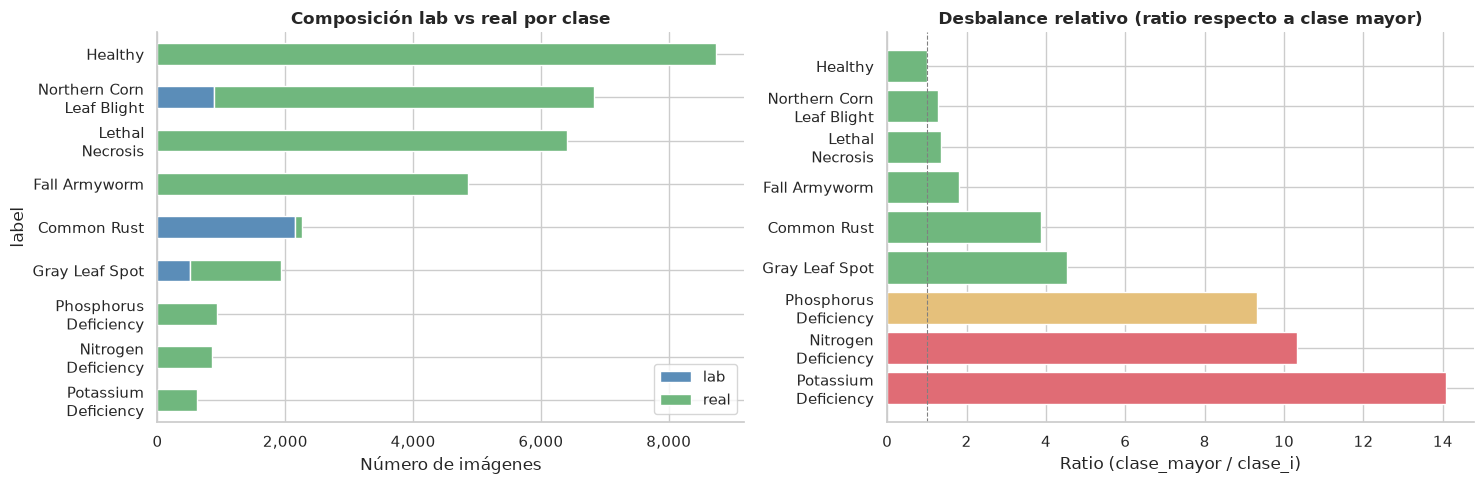


Ratio de desbalance máximo: 14.1x  ('potassium_deficiency' vs 'healthy')


In [13]:
biases = [
    {
        "clase":   "common_rust",
        "sesgo":   "Dominio de imágenes de laboratorio (95.4%)",
        "detalle": (
            "2,150 de 2,256 imágenes provienen de entorno controlado (PlantVillage via cropdg y maize_desease). "
            "El modelo podría aprender el fondo uniforme negro/blanco en lugar de los síntomas foliares reales. "
            "Solo 106 imágenes en campo."
        ),
        "riesgo": "Alto",
    },
    {
        "clase":   "gray_leaf_spot",
        "sesgo":   "Predominio de campo real, fuentes diversificadas (ago. 2026)",
        "detalle": (
            "513 lab (todas de PlantVillage/cropdg) y 1,417 real repartidas en tres fuentes: "
            "maize_field (606), corn_leaf_diseases_classification_roboflow (480) y maize_leaf_roboflow (331). "
            "La ampliación de agosto 2026 corrigió la dependencia de una sola fuente de campo."
        ),
        "riesgo": "Bajo-Medio",
    },
    {
        "clase":   "northern_corn_leaf_blight",
        "sesgo":   "Alta proporción real, pero dominada por una sola fuente",
        "detalle": (
            "5,942 imágenes reales, de las cuales ~4,223 originalmente provenían de maize_africa (eliminados como duplicados). "
            "La representación geográfica podría ser limitada a condiciones de África subsahariana."
        ),
        "riesgo": "Medio",
    },
    {
        "clase":   "fall_armyworm",
        "sesgo":   "Heterogeneidad visual intraclase: daño vs. daño + gusano",
        "detalle": (
            "Las imágenes mezclan dos señales visuales distintas según la fuente: (1) hoja con daño foliar "
            "sin insecto visible (corn_leaf_roboflow y maize_africa/Activity), y (2) hoja con daño y gusano "
            "visible (maize_africa/Pest y multicrop). El modelo puede aprender atajos de textura del insecto "
            "en lugar del patrón de daño foliar, o fallar cuando el gusano no está presente."
        ),
        "riesgo": "Medio-Alto",
    },
    {
        "clase":   "deficiencias nutricionales",
        "sesgo":   "Baja representación (fuente única ya resuelta en ago. 2026)",
        "detalle": (
            "Nitrogen (846), Phosphorus (938) y Potassium (621). Ya no dependen de una sola fuente: "
            "cada una combina cuatro (corn_leaf_roboflow, maize_2_roboflow, maize_nutrient y "
            "maize_deficiency_scanner_roboflow), con resoluciones heterogéneas en vez de 640x640 fijo. "
            "Siguen siendo las clases minoritarias: Potassium es la más escasa (14.1x vs healthy)."
        ),
        "riesgo": "Medio",
    },
]

print(f"{'CLASE':<35} {'RIESGO':<12} {'DESCRIPCIÓN'}")
print("-" * 100)
for b in biases:
    print(f"{b['clase']:<35} {b['riesgo']:<12} {b['sesgo']}")
    print(f"  - {b['detalle'][:110]}...")
    print()

# Visualización: composición lab/real + ratio de desbalance
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df_plot = df.set_index("label")[["lab", "real"]]
df_plot.plot(kind="barh", stacked=True, ax=axes[0],
             color=["#5B8DB8", "#70B77E"], edgecolor="white")
axes[0].set_title("Composición lab vs real por clase", fontweight="bold")
axes[0].set_xlabel("Número de imágenes")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].invert_yaxis()

ratio = df["total"].max() / df["total"]
ratio_df = pd.DataFrame({"label": df["label"], "ratio": ratio})
colors_r = ["#E06C75" if r > 10 else "#E5C07B" if r > 5 else "#70B77E"
            for r in ratio_df["ratio"]]
axes[1].barh(ratio_df["label"], ratio_df["ratio"], color=colors_r, edgecolor="white")
axes[1].axvline(1, color="gray", linestyle="--", linewidth=0.8)
axes[1].set_title("Desbalance relativo (ratio respecto a clase mayor)", fontweight="bold")
axes[1].set_xlabel("Ratio (clase_mayor / clase_i)")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(TMP_DIR / "eda_06_sesgos.png", dpi=150, bbox_inches="tight")
plt.show()

max_idx = ratio.idxmax()
min_idx = ratio.idxmin()
print(f"\nRatio de desbalance máximo: {ratio.max():.1f}x  ({df.loc[max_idx, 'clase']!r} vs {df.loc[min_idx, 'clase']!r})")

---

## Conclusiones

1. **Desbalance severo:** La clase `healthy` (8 744) supera en **14.1x** a `potassium_deficiency` (621). Esto requiere muestreo ponderado o un techo máximo por clase durante el entrenamiento. El ratio venía de 32.9x antes de la ampliación de agosto 2026; sigue siendo alto y las cuatro clases minoritarias (`potassium` 14.1x, `nitrogen` 10.3x, `phosphorus` 9.3x, `gray_leaf_spot` 4.5x) continúan por encima del umbral de 4x.

2. **Sesgo de dominio en `common_rust`:** El 95.4 % de las imágenes proviene de entorno controlado (fondo uniforme). El modelo podría aprender el fondo y no los síntomas. Se recomienda data augmentation agresivo (fondos aleatorios, variación de iluminación) y ampliar las imágenes de campo.

3. **Resolución heterogénea:** El dataset mezcla imágenes con resoluciones muy dispares. Las de `corn_leaf_roboflow` ya vienen fijas a 640x640 px, pero los cuatro datasets Roboflow de agosto 2026 conservan la resolución original de cámara (hasta 4096 x 3072 px, con 36 resoluciones distintas en uno de ellos), acentuando la dispersión. El pipeline de entrenamiento debe aplicar redimensionamiento consistente a la resolución de entrada del modelo.

4. **Duplicados controlados (8 599 eliminadas):** Se eliminaron **8 599 imágenes** agrupadas en **8 110 grupos** detectados por pHash. Las principales fuentes de duplicados fueron `maize_desease` (6 508), `multi_desease` (1 980) y `maize_africa` (51). De ese total, **61 imágenes en 60 grupos** corresponden a la ampliación de agosto 2026, y quedaron **contenidas por completo dentro de los datasets nuevos**: no se detectó ni un solo duplicado contra el material preexistente de `clean/`.

5. **Fuentes diversificadas en clases pequeñas (resuelto en ago. 2026):** `potassium_deficiency`,
   `nitrogen_deficiency` y `phosphorus_deficiency` dependían de una sola fuente (`maize_nutrient`).
   Tras la ampliación cada una combina **cuatro** fuentes distintas, y `gray_leaf_spot` pasó de una
   a tres en su porción de campo. Siguen siendo las clases con menos imágenes, pero el riesgo de
   sobreajuste a las condiciones de captura de una única fuente se redujo de forma sustancial.

---

> **Nota de versión.** Este notebook corresponde al estado del dataset **posterior a la primera
> entrega** (ampliación de agosto 2026: 33 438 imágenes). La versión de la primera etapa
> (31 622 imágenes) se conserva congelada en `reports/firts-phase/01_eda_first_phase.ipynb`,
> junto con su salida estática renderizada `01_eda_first_phase.html`.
